# Modelling Viewcount growth of top 500 movies post 2000

Inspired by the Paper "Bio-Inspired Models for Characterizing YouTube Viewcount", a review of a movie is counted as a view. The top 500 most reviewed movies post 2000 are then compared with two bio isnpired viewcount models and classfied into "viral" or "non-viral" movies. The models used for this calssification are the "Gompertz-Model" and the "negative exponetial modell". Both assume a fixed target population, which seams fitting for a movie release. ANd the negative exponential model tries to model the popularity gained via braodcasted advertisement, which also is pretty fitting

In [1]:
import pandas as pd
import numpy as np

TOP_N = 500

In [2]:
movies_dtype = {
    "movieId": "int32",
    "title": "string",
    "genres": "string"
}
ratings_dtype = {
    "userId": "int32",
    "movieId": "int32",
    "rating": "float32",
    "timestamp": "int64"
}
movies_df = pd.read_csv("./../data/ml-latest/movies.csv", dtype=movies_dtype)
ratings_df = pd.read_csv("./../data/ml-latest/ratings.csv", dtype=ratings_dtype)


# Fill in release year based on regex from title as col
movies_df["year"] = movies_df["title"].str.extract(r"\((\d{4})\)").astype("Int64")
recent_movies = movies_df[movies_df["year"] >= 2000].copy()


recent_movie_ids = recent_movies["movieId"]
review_counts = ratings_df["movieId"].value_counts()
review_counts.head()
recent_movie_review_counts = review_counts[review_counts.index.isin(recent_movie_ids)]

top_movie_ids = recent_movie_review_counts.nlargest(TOP_N).index.values

# Filter the movies
movies_df = recent_movies[recent_movies["movieId"].isin(top_movie_ids)]
ratings_df = ratings_df[ratings_df["movieId"].isin(top_movie_ids)]

In [3]:
movie_time_series = {}

for movie_id in movies_df["movieId"]:
    movie_ratings = ratings_df[ratings_df["movieId"] == movie_id].sort_values("timestamp")
    timestamps = movie_ratings["timestamp"].values


    elapsed_time = timestamps - timestamps[0]
    total_time = elapsed_time[-1]

    cumulative_counts = np.arange(1, len(movie_ratings) + 1, dtype=float)
    max_count = cumulative_counts[-1]

    t_norm = elapsed_time / total_time if total_time > 0 else elapsed_time
    y_norm = cumulative_counts / max_count

    movie_time_series[movie_id] = {
        "title": movies_df.loc[movies_df["movieId"] == movie_id, "title"].values[0],
        "t": t_norm,
        "y": y_norm,
        "total_reviews": max_count,
        "avg_rating": movie_ratings["rating"].mean()
    }

In [7]:
# Viral, Fixed Target Population
def logistic(t, lam):
    S0 = y_first
    M = 1.0
    return M/(1+((M-S0)/S0)*np.exp(-lam*M*t))

def gompertz(t, lam):
    S0 = y_first
    M = 1.0
    return M*np.exp(-np.log(M/S0)*np.exp(-lam*t))


# Non-viral, Fixed target population
def neg_exponential(t, lam):
    S0 = y_first
    M = 1.0
    return S0 + (M - S0) * (1.0 - np.exp(-lam * t))


# Non-viral, Growing target population
def linear(t, lam):
    S0 = y_first
    return S0 + lam * t

def mod_neg_exponential(t, lam, k):
    S0 = y_first
    M = 1.0
    return S0 + (M - S0) * (1.0 - np.exp(-lam*t)) + k * t


# Viral, Growing target population
def mod_gompertz(t, lam, k):
    S0 = y_first
    M = 1.0
    return M * np.exp(-np.log(M / S0) * np.exp(-lam * t)) + k * t

models = {
    "Logistic": logistic,
    "Gompertz": gompertz,
    "Negative Exponential": neg_exponential,
    "Linear": linear,
    "Mod. Neg. Exponential": mod_neg_exponential,
    "Mod. Gompertz": mod_gompertz
}

In [ ]:
from scipy.optimize import curve_fit

results = []

for movie_id, data in movie_time_series.items():
    t_vals = data["t"]
    y_vals = data["y"]

    global y_first
    y_first = y_vals[0] if y_vals[0] > 0 else 1e-5


    best_model = None
    best_gof = np.inf
    best_metrics = (None, None, None)

    for name, model in models.items():

        p0 = [1.0, 0.1] if "Mod." in name else [1.0]
        popt, _ = curve_fit(model, t_vals, y_vals, p0=p0, method="lm")

        y_pred = model(t_vals, *popt)
        
        mse = np.mean((y_vals - y_pred) ** 2)
        mer = np.mean(np.abs(y_vals - y_pred) / (y_vals + 1e-10))

        msc = np.sum((y_pred - y_vals) ** 2)
        df = len(y_vals) - len(popt)
        gof = (1 / df) * msc if df > 0 else np.inf
        best_metrics = (mse,mer,gof)

        if gof < best_gof:
            best_gof = gof
            best_model = name
            best_metrics = (mse, mer, gof)


    results.append({
        "movieId": movie_id,
        "title": data["title"],
        "total_reviews": data["total_reviews"],
        "avg_rating": data["avg_rating"],
        "best_model": best_model,
        "MSE": best_metrics[0],
        "MER": best_metrics[1],
        "GOF": best_metrics[2]
    })
    
df_results = pd.DataFrame(results)
model_counts = df_results["best_model"].value_counts()
print(f"Model Distribution across Top {TOP_N} Movies:")
print(model_counts)

/tmp/ipykernel_53774/1727188360.py:20: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(model, t_vals, y_vals, p0=p0, method="lm")


,movieId,title,total_reviews,avg_rating,best_model,MSE,MER,GOF
0,3273,Scream 3 (2000),8726.0,2.449003,Mod. Neg. Exponential,0.012743,0.321467,0.012746
1,3275,"Boondock Saints, The (2000)",13251.0,3.860463,Mod. Gompertz,0.001297,0.212568,0.001298
2,3285,"Beach, The (2000)",8589.0,3.106008,Mod. Neg. Exponential,0.005320,0.235000,0.005321
3,3300,Pitch Black (2000),12062.0,3.467957,Mod. Neg. Exponential,0.002872,0.179055,0.002872
4,3301,"Whole Nine Yards, The (2000)",9892.0,3.350384,Mod. Neg. Exponential,0.006872,0.251763,0.006873


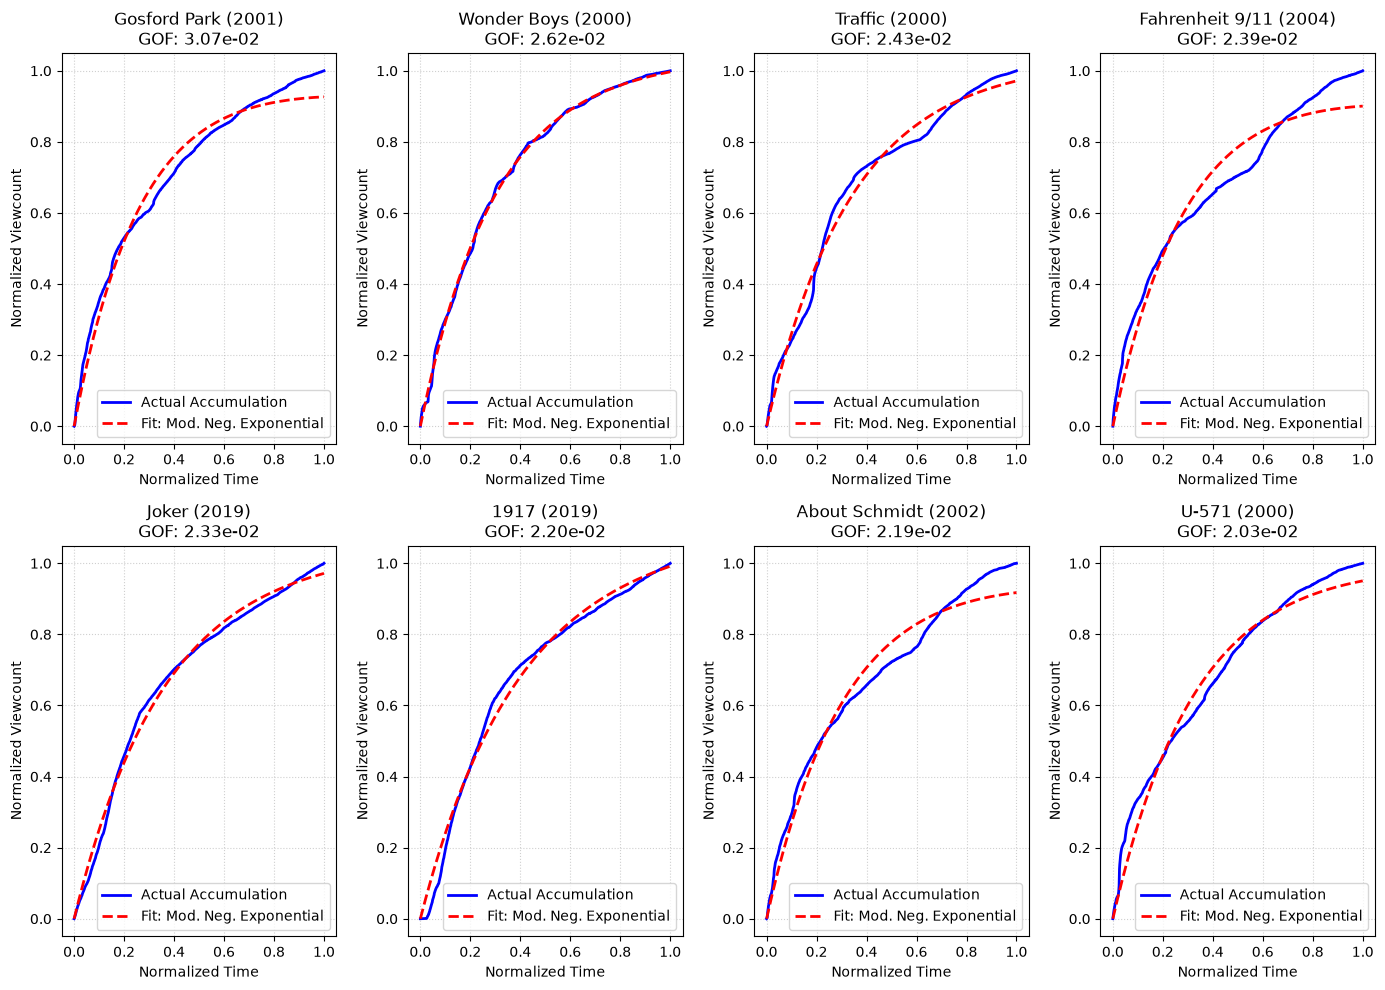

In [16]:
import matplotlib.pyplot as plt

# 1. Filter for the two target models and get the top 4 best fits (lowest GOF)
target_models = ["Mod. Neg. Exponential", "Mod. Gompertz"]
top_4_movies = (df_results[df_results["best_model"].isin(target_models)]
                .sort_values(by="GOF", ascending=False)
                .head(8))

# 2. Set up a 2x2 grid for plotting
fig, axes = plt.subplots(2, 4, figsize=(14, 10))
axes = axes.flatten()

# 3. Iterate through the top 4 movies and plot
for idx, (_, row) in enumerate(top_4_movies.iterrows()):
    movie_id = row["movieId"]
    model_name = row["best_model"]
    title = row["title"]
    
    # Retrieve actual data
    data = movie_time_series[movie_id]
    t_vals = data["t"]
    y_vals = data["y"]
    
    # Set the global y_first expected by your model definitions
    global y_first
    y_first = y_vals[0] if y_vals[0] > 0 else 1e-5
    
    # Re-fit to get the curve parameters for plotting
    model_func = models[model_name]
    p0 = [1.0, 0.1]
    popt, _ = curve_fit(model_func, t_vals, y_vals, p0=p0, method="lm")
    y_pred = model_func(t_vals, *popt)
    
    # Plotting
    ax = axes[idx]
    ax.plot(t_vals, y_vals, label="Actual Accumulation", color="blue", linewidth=2)
    ax.plot(t_vals, y_pred, label=f"Fit: {model_name}", color="red", linestyle="--", linewidth=2)
    
    ax.set_title(f"{title}\nGOF: {row['GOF']:.2e}")
    ax.set_xlabel("Normalized Time")
    ax.set_ylabel("Normalized Viewcount")
    ax.legend()
    ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()